# Matcha — baseline recommender

**The question:** given one track, which other tracks sound like it?

This notebook goes from raw audio features to a working recommender and an
honest score for it. Four steps:

1. **Load and scale** 518 audio features for 8,000 tracks
2. **Explore** — what the feature set is actually made of, and where it misbehaves
3. **Reduce** with PCA, and log the run to MLflow
4. **Recommend and measure** — the model, then four different rulers for it

Everything heavy lives in `modeling/`. The cells here call it, so the same code
runs from a notebook, a script, or the command line.

> **Before running:** the MLflow server must be up in its own terminal
> (`make mlflow`). Restart the kernel first if `modeling/` has changed since you
> last ran — Python caches imported modules.

In [ ]:
import sys

# make the modeling package importable from inside notebooks/
sys.path.append("..")

import pandas as pd
import numpy as np

from modeling.data import load_fma

# Features (518 audio descriptors) and matching metadata for the 'small' subset
X_small, small_tracks = load_fma(subset="small")

print(f"Data successfully loaded. Shape: {X_small.shape}")

In [11]:
print("small_tracks shape:", small_tracks.shape)
print("X_small shape:", X_small.shape)

small_tracks shape: (8000, 52)
X_small shape: (8000, 518)


In [ ]:
from modeling.features import scale_features

X_scaled_df, scaler = scale_features(X_small)
print("Scaled features shape:", X_scaled_df.shape)

## Exploring the feature set

The 518 columns are not 518 independent facts about a track. They are eleven
families of audio descriptor, each summarised by seven statistics — and the
families are wildly unequal in size.

That matters because PCA picks its directions by variance, and a concept's
variance grows with the number of columns representing it. A family with 84
columns shouts; a family with 7 whispers.

The next two cells look at that imbalance, and at how far the features depart
from the well-behaved, symmetric spread `StandardScaler` assumes.

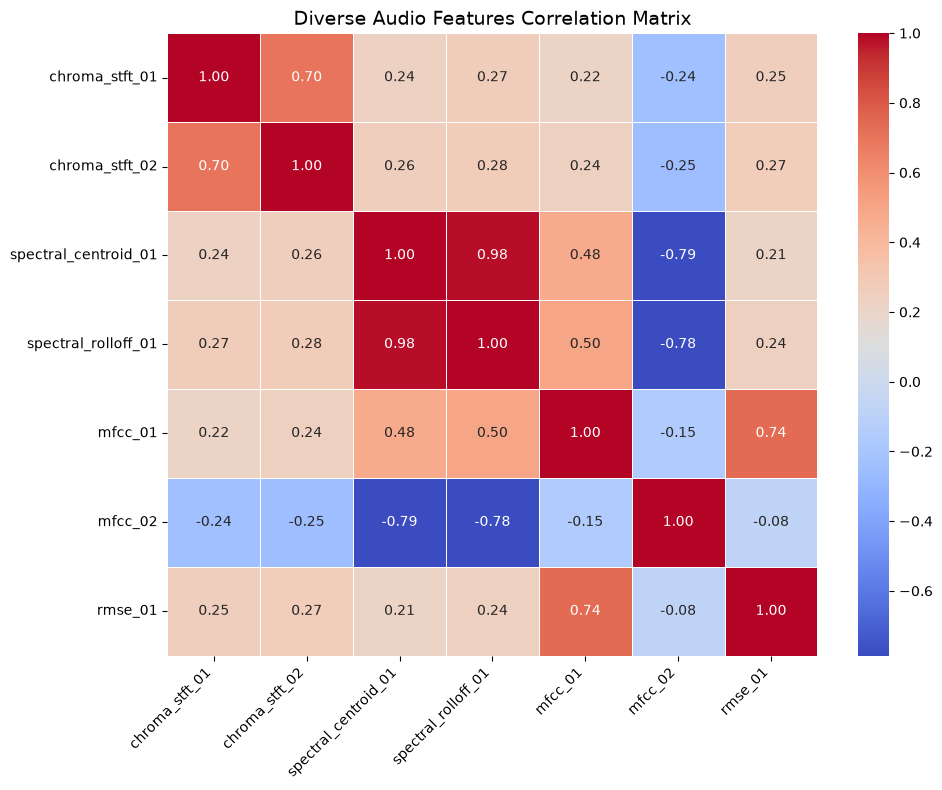

In [16]:
import seaborn as sns
import matplotlib.pyplot as plt

# Explicitly pick 1 feature from each category
target_features = ['chroma_stft', 'spectral_centroid', 'spectral_rolloff', 'mfcc', 'rmse']
selected_cols = []

for feat in target_features:
    matching = [col for col in X_scaled_df.columns if col[0] == feat and col[1] == 'mean']
    if matching:
        selected_cols.extend(matching[:2])  # Take first 2 channels/dimensions of each

df_analysis = X_scaled_df[selected_cols].copy()
df_analysis.columns = [f"{col[0]}_{col[2]}" for col in df_analysis.columns]

# Compute & Plot
plt.figure(figsize=(10, 8))
sns.heatmap(df_analysis.corr(), annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Diverse Audio Features Correlation Matrix', fontsize=14)
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

In [ ]:
# Two things about the feature set that shape every later decision.
from modeling.evaluation import feature_family_summary, statistic_summary, tail_summary

families = feature_family_summary(X_small)
stats = statistic_summary(X_small)

print("columns per feature family")
print(families.to_string())

chroma = families[families.index.str.startswith("chroma")].sum()
print(f"\nthe three chroma families alone: {chroma} of {X_small.shape[1]} columns "
      f"({chroma / X_small.shape[1]:.0%})")
print("they all measure harmonic content, just by different extraction methods —")
print("so PCA, which picks directions by variance, leans heavily on harmony.")
print(f"meanwhile zcr and rmse (rhythm, texture) get {families['zcr']} columns each.\n")

print("columns per summary statistic")
print(stats.to_string())

tails = tail_summary(X_small, X_scaled_df)
print(f"\ntail heaviness")
print(f"  columns with kurtosis > 100 : {tails['columns_kurtosis_over_100']} of {tails['n_columns']}")
print(f"  max kurtosis                : {tails['max_kurtosis']:.0f}   (a normal distribution is 0)")
print(f"  max |z| after StandardScaler: {tails['max_abs_z']:.1f}   (std deviations from the mean)")
print("\nkurtosis and skew are heavy-tailed by construction, and that is 148 of the 518")
print("columns. RobustScaler is the obvious fix — we tested it and it scored worse")
print("(0.336 vs 0.413), so those outliers carry real signal.")

## Reducing to a feature space

518 dimensions is more than the recommender needs, and distance calculations get
slower and noisier as dimensions pile up.

PCA finds the directions along which tracks differ most and keeps only those. We
ask for **90% of the variance**, which works out at 146 components — the
conventional, defensible default. Not necessarily the optimal one; the tooling
below will tell us.

`N_COMPONENTS` at the top of the next cell is the only knob. `0.90` is a
variance target, `60` would be a fixed component count — the run name, the
artifact filenames and the logged parameters all follow from it.

In [ ]:
import matplotlib.pyplot as plt
import mlflow

from modeling.config import TRACKING_URI, MUSIC_EXPERIMENT_NAME
from modeling.data import genre_labels
from modeling.evaluation import neighbour_genre_agreement, random_baseline
from modeling.features import (
    explained_variance_curve,
    components_for_variance,
    fit_pca,
    transform,
    save_artifacts,
    pca_tag,
)

# ⬇️ the only knob. Two forms, both valid:
#      0.90  (float) -> keep enough components for 90% of the variance -> 146
#      60    (int)   -> keep exactly 60 components
#    Run name, artifact names and logged params all follow from it.
N_COMPONENTS = 0.90

# TRACKING_URI comes from .mlflow_uri via modeling/config.py.
# Without set_tracking_uri, MLflow writes to a local store next to the notebook
# and nothing ever shows up in the UI on port 5000.
mlflow.set_tracking_uri(TRACKING_URI)
mlflow.set_experiment(MUSIC_EXPERIMENT_NAME)
print("tracking to:", mlflow.get_tracking_uri())

# 1. Variance curve over all possible components (independent of the target)
cumulative_variance = explained_variance_curve(X_scaled_df)
n_90 = components_for_variance(cumulative_variance, 0.90)
n_95 = components_for_variance(cumulative_variance, 0.95)
n_99 = components_for_variance(cumulative_variance, 0.99)
print(f"components needed — 90%: {n_90}, 95%: {n_95}, 99%: {n_99}")

# 2. Plot Explained Variance
tag = pca_tag(N_COMPONENTS)
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(cumulative_variance, marker='o', linestyle='--', color='b')
ax.axhline(y=0.90, color='r', linestyle=':', label='90% Variance Threshold')
ax.set_xlabel('Number of Components')
ax.set_ylabel('Cumulative Explained Variance')
ax.set_title('PCA - Cumulative Explained Variance Ratio', fontsize=14)
ax.grid(True)
ax.legend()
plt.show()

# 3. Fit at the target size
pca = fit_pca(X_scaled_df, n_components=N_COMPONENTS)

# 4. The metric that actually reflects what the recommender needs:
#    of a track's 10 nearest neighbours, how many share its genre.
#    Explained variance can't tell us this — see modeling/evaluation.py.
labels = genre_labels(small_tracks)
X_pca = transform(X_small, scaler, pca)
quality = neighbour_genre_agreement(X_pca, labels)
print(f"neighbour genre agreement: {quality:.3f}  (random = {random_baseline(labels):.3f})")

with mlflow.start_run(run_name=f"PCA_{tag}"):
    mlflow.log_params({
        "dataset": "fma_small",
        "original_features_count": int(X_scaled_df.shape[1]),
        "n_samples": int(X_scaled_df.shape[0]),
        "scaler": "StandardScaler",
        "pca_target": N_COMPONENTS,
    })
    mlflow.log_metrics({
        "neighbour_genre_agreement": quality,
        "random_baseline": random_baseline(labels),
        "n_components_selected": pca.n_components_,
        "total_explained_variance": float(pca.explained_variance_ratio_.sum()),
        "explained_variance_pc1": float(pca.explained_variance_ratio_[0]),
    })

    mlflow.log_figure(fig, f"pca_cumulative_variance_{tag}.png")

    # suffix keeps e.g. pca_90pct.pkl and pca_60dims.pkl side by side in models/
    scaler_path, pca_path = save_artifacts(scaler, pca, suffix=f"_{tag}")
    mlflow.log_artifact(str(scaler_path))
    mlflow.log_artifact(str(pca_path))

    mlflow.set_tag("stage", "eda-baseline")

    print("✅ Run logged to MLflow successfully!")
    print(f"   {tag}: {pca.n_components_} components, quality {quality:.3f}")

## The baseline recommender

Everything above builds a **feature space** — it reduces 518 audio descriptors to
146 components. That is preprocessing, not a model: nothing so far can take a
track and return anything.

The model is the step that uses that space to answer *"what sounds like this?"*.
The baseline answer is the simplest one available: **the closest tracks by
distance**. No genre filtering, no popularity weighting, no learned similarity —
so that every later idea has something honest to beat.

The next cell does it in four visible steps. The cell after that is the same
thing imported from `modeling/recommender.py`.

In [ ]:
import pandas as pd
from sklearn.neighbors import NearestNeighbors

from modeling.features import transform

SEED_TRACK = 2   # AWOL — Food [Hip-Hop]

# ---- step 1: put every track in the PCA space -------------------------------
# scaler.transform then pca.transform, keeping the track ids as the index.
X_pca = transform(X_small, scaler, pca)
print("step 1 — catalogue projected:", X_pca.shape, "(tracks x components)")

# ---- step 2: index the catalogue --------------------------------------------
# cosine compares the *direction* of two feature vectors and ignores their
# magnitude, so a loud track and a quiet one with the same character stay close.
index = NearestNeighbors(metric="cosine").fit(X_pca)
print("step 2 — indexed with cosine distance")

# ---- step 3: look up one track's neighbours ---------------------------------
row = X_pca.index.get_loc(SEED_TRACK)
distances, positions = index.kneighbors(X_pca.iloc[[row]], n_neighbors=11)

# a track is always its own nearest neighbour at distance 0 — drop it
distances, positions = distances[0][1:], positions[0][1:]
neighbour_ids = X_pca.index[positions]
print(f"step 3 — closest tracks to {SEED_TRACK}: {list(neighbour_ids[:3])} ...")

# ---- step 4: attach names so the result is readable -------------------------
meta = small_tracks.loc[neighbour_ids]
recommendations = pd.DataFrame({
    "distance": distances,
    "artist": meta[("artist", "name")].values,
    "title": meta[("track", "title")].values,
    "genre": meta[("track", "genre_top")].values,
}, index=neighbour_ids)

seed = small_tracks.loc[SEED_TRACK]
print(f"\nseed track: {seed[('artist', 'name')]} — {seed[('track', 'title')]} "
      f"[{seed[('track', 'genre_top')]}]\n")
recommendations

In [ ]:
# The same four steps, packaged. modeling/recommender.py does exactly what the
# cell above does — this is the version to import elsewhere.
from modeling.recommender import TrackRecommender

rec = TrackRecommender(scaler, pca, metric="cosine").fit(X_small, small_tracks)

print("seed:", rec.describe(SEED_TRACK), "\n")
rec.similar_to(SEED_TRACK, n=10)

## Scoring it — four rulers, because one lies

A single number can always be gamed. Each of these is blind to something the
others catch:

| Ruler | What it asks | What it misses on its own |
|---|---|---|
| `precision@10` | how many of the ten share the seed's genre | treats slot 1 and slot 10 alike |
| `nDCG@10` | are the good ones near the **top** | same hard genre boundary |
| `genre_overlap@10` | how much the full genre lists overlap | ordering |
| `coverage` | how much of the catalogue ever appears | quality — a random model scores well here |

**Why the third one matters for us.** Our product is built on a Familiar →
Adventurous control, and an adventurous recommendation deliberately leaves the
seed's genre. Exact matching scores that as *wrong* — so with only `precision`,
week 2's headline feature would read as a regression the moment it works.
Overlap grades the distance instead, which is how we tell smart exploration from
random noise.

One caveat worth repeating: genre is a **proxy**, not truth. Two tracks can be
similar and carry different labels. These numbers compare configurations
honestly; they do not measure how good the recommender feels to a listener.

In [ ]:
# How good is the baseline? Four rulers, because no single one tells the whole story.
from modeling.evaluation import (
    catalogue_coverage,
    genre_overlap_at_k,
    genre_sets,
    ndcg_at_k,
    random_baseline,
)
from modeling.recommender import precision_at_k

K = 10
gsets = genre_sets(small_tracks)   # every genre per track, not just the top one

# 1. precision@k — of the K recommended tracks, how many share the seed's top genre
score = precision_at_k(rec, labels, k=K, sample=None)

# 2. nDCG@k — same idea, but a hit near the top of the list counts for more
ndcg = ndcg_at_k(X_pca, labels, k=K)

# 3. genre overlap — graded instead of right/wrong, so a cross-genre jump to a
#    related genre scores above a jump to an unrelated one. This is the ruler
#    that will still be fair once the Familiar->Adventurous control exists.
overlap = genre_overlap_at_k(X_pca, gsets, k=K)

# 4. coverage — does the recommender surface the catalogue, or the same few tracks?
coverage = catalogue_coverage(X_pca, k=K)

print(f"precision@{K}      : {score:.3f}   (random {random_baseline(labels):.3f}, "
      f"lift {score / random_baseline(labels):.1f}x)")
print(f"nDCG@{K}           : {ndcg:.3f}")
print(f"genre_overlap@{K}  : {overlap:.3f}")
print(f"coverage           : {coverage:.3f}   "
      f"({int(coverage * len(X_pca))} of {len(X_pca)} tracks ever recommended)")

with mlflow.start_run(run_name=f"PCA_{tag}_eval"):
    mlflow.log_params({
        "k": K,
        "metric": "cosine",
        "pca_target": N_COMPONENTS,
        "n_components": int(pca.n_components_),
    })
    mlflow.log_metrics({
        "precision_at_k": score,
        "ndcg_at_k": ndcg,
        "genre_overlap_at_k": overlap,
        "catalogue_coverage": coverage,
        "random_baseline": random_baseline(labels),
    })
    mlflow.set_tag("stage", "baseline-eval")
    print("\nlogged to MLflow:", mlflow.active_run().info.run_id)

## Validating on tracks the pipeline has never seen

Everything above fits the scaler and PCA on all 8,000 tracks and then scores
those same tracks. For a fixed catalogue that is defensible, but it cannot
answer the question a reviewer will ask: **does this work for a track the
pipeline has never seen?**

So this is the k-fold version. In each of 5 folds:

- the scaler and PCA are fitted on the training tracks **only**
- the training tracks become the catalogue
- each held-out track is projected into that space and retrieves from it

Note there is no `y_train` / `y_test` here. This model has no target to predict —
it learns nothing from the genre labels, it only measures distance. Genre is
used *after the fact* to check whether the retrieved tracks look sensible. That
is why the split is on `X` alone.

Held-out tracks are not in the catalogue, so unlike the cells above there is no
self-match to drop.

In [ ]:
# 5-fold held-out evaluation. Takes a few minutes — PCA is refitted per fold.
# Passing genre_sets_ makes the folds report all four rulers, not just precision,
# so the held-out column lines up one-for-one with the in-sample one above.
from modeling.evaluation import cross_validated_precision

folds = cross_validated_precision(
    X_small, labels,
    n_components=N_COMPONENTS,   # same setting as the baseline above
    metric="cosine",
    k=K,
    n_splits=5,
    genre_sets_=gsets,
)

shown = ["fold", "components", "precision_at_k", "ndcg_at_k", "genre_overlap_at_k", "coverage"]
print(folds[shown].to_string(index=False, float_format=lambda v: f"{v:.3f}"))

in_sample = {
    "precision_at_k": score,
    "ndcg_at_k": ndcg,
    "genre_overlap_at_k": overlap,
    "coverage": coverage,
}

print(f"\n{'metric':22s} {'held-out':>18s}   {'in-sample':>9s}   gap")
for m, insample in in_sample.items():
    mean, spread = folds[m].mean(), folds[m].std()
    print(f"{m:22s} {mean:.3f} +/- {spread:.3f}   {insample:9.3f}   {(insample - mean) / insample:+.1%}")

print("\nCoverage is the one to read differently: held-out, only the 1600 test tracks")
print("query a 6400-track catalogue, so a lower number is expected, not a warning.")

# Log it next to the run from the eval cell, so the baseline carries both protocols.
with mlflow.start_run(run_name=f"PCA_{tag}_kfold"):
    mlflow.log_params({"n_splits": 5, "metric": "cosine", "pca_target": N_COMPONENTS, "k": K})
    for m in in_sample:
        mlflow.log_metric(f"{m}_heldout", folds[m].mean())
        mlflow.log_metric(f"{m}_heldout_std", folds[m].std())
        mlflow.log_metric(f"{m}_insample", in_sample[m])
    mlflow.set_tag("stage", "validation")
    print("\nlogged to MLflow:", mlflow.active_run().info.run_id)

## Familiar → Adventurous

### The problem with being right

Ask the baseline for tracks like a hip-hop seed and it returns:

```
ranks 1-5:   Hip-Hop, Hip-Hop, Hip-Hop, Electronic, Hip-Hop
```

That is a good answer. It is also a useless one after the third time. The
listener already likes hip-hop — we handed back more of what they walked in
with. Every recommender that only ever answers *"the most similar"* ends in the
same place: a closed room.

Now look at ranks 31-35 of the **same** ranked list, same seed:

```
ranks 31-35: International, Rock, Pop, Instrumental, Pop
```

Not one of them is hip-hop. These are discoveries — and they can *never* surface
in a top-10, because thirty hip-hop tracks sit in front of them. If you always
read from position 1, this music is invisible.

**That is why the starting position matters.** Our product is a bridge. A bridge
that never leaves the first ten is just a floor.

### Why not random, then?

Because a random track out of 8,000 is almost certainly unrelated, the listener
dislikes it once, and never trusts the button again.

Rank 200 is a different thing entirely: 7,799 tracks are *less* related than it
is. Still the top 2.5% by similarity. Far away, but **chosen**.

```
rank 1 ──────── rank 30 ──────── rank 500 ──────── random
repetitive      new but related   far but chosen    noise
```

The baseline only ever occupied the far left. The dial lets the listener stand
anywhere on that line.

### How it works — no second model

The model already ranks **all 7,999** other tracks. We just never looked past
the first ten:

```
nearest ──────────────────────────────────────────▶ furthest
[1][2][3][4][5][6][7][8][9][10] [11] ... [500] ... [7999]
└──── what the baseline shows ──┘
```

So the control slides a window of ten down a list that already exists. Nothing
is refitted; only the slice index changes.

`adventure` runs 0 → 1 and maps **geometrically** onto the starting rank —
`500 ** adventure`:

| adventure | starting rank |
|---|---|
| 0.00 | 1 — the baseline, byte for byte |
| 0.25 | 5 |
| 0.50 | 22 |
| 0.75 | 106 |
| 1.00 | 500 |

Geometric rather than linear because distance grows slowly with rank: ranks 1-5
sit at cosine 0.42-0.48, ranks 31-35 at 0.55, ranks 201-205 at 0.66. Ranks 50
and 100 sound alike; ranks 1 and 20 do not. A linear dial would compress the
entire audible range into its first 4% of travel, then do nothing for the rest.
This one moves slowly where the ear notices and fast where it does not.


In [ ]:
# The whole mechanism, in the open — before using the packaged version below.
from modeling.recommender import depth_for

# ---- the ranking already exists -------------------------------------------
# One query, deep enough to reach rank 510. The baseline asked for 11 and threw
# the rest away; the list itself is no different.
row = X_pca.index.get_loc(SEED_TRACK)
distances, positions = index.kneighbors(X_pca.iloc[[row]], n_neighbors=511)
distances, positions = distances[0][1:], positions[0][1:]   # drop the seed itself

print(f"the model ranked {len(X_pca) - 1} other tracks; we fetched {len(positions)} of them")
print(f"rank   1 -> distance {distances[0]:.3f}")
print(f"rank  22 -> distance {distances[21]:.3f}")
print(f"rank 500 -> distance {distances[499]:.3f}")
print("\ndistance climbs slowly, which is exactly why the dial is not linear.\n")

# ---- the dial only picks where to start reading ----------------------------
for level, name in [(0.0, "FAMILIAR"), (0.5, "BRIDGE"), (1.0, "ADVENTUROUS")]:
    start = depth_for(level)          # 500 ** level, minus one for 0-based
    window = slice(start, start + 5)  # <- the entire feature, one line

    ids = X_pca.index[positions[window]]
    meta = small_tracks.loc[ids]

    print(f"{name:12s} adventure {level:.1f}  ->  ranks {start + 1}-{start + 5}")
    print(pd.DataFrame({
        "distance": distances[window],
        "artist": meta[("artist", "name")].values,
        "genre": meta[("track", "genre_top")].values,
    }).to_string(index=False, float_format=lambda v: f"{v:.3f}"), "\n")


In [ ]:
# The same thing, packaged: modeling/recommender.py does exactly the cell above.
# `adventure` defaults to 0.0, so every existing call behaves as it always did.
rec.similar_to(SEED_TRACK, n=5, adventure=0.75)


### What does it cost?

One seed track is an anecdote. The cell above happens to look good; it would
look good even if the feature were broken, because we chose the seed.

So ask the same question of 1,000 tracks at once, at five depths, using the
rulers the baseline is already scored on. Expect `precision@10` to **fall** —
that is the feature working, not a regression. What we are actually looking for
is three things:

1. **Is there a cliff?** A depth where relevance collapses would mean capping
   the dial before it.
2. **Where does it end up?** If the far end lands at random (0.125), we built a
   shuffle button and should say so.
3. **Does `genre_overlap` hold up better than exact matching?** That would mean
   the far recommendations are still musically related, not merely distant.

This is the cell that decides whether the dial ships as a continuous slider or
as three safe presets.


In [ ]:
# 1,000 seeds, five depths, the same rulers as the baseline scorecard.
from modeling.evaluation import depth_profile

profile = depth_profile(X_pca, labels, genre_sets_=gsets, k=K, sample=1000)
print(profile.to_string(index=False, float_format=lambda v: f"{v:.3f}"))

rnd = random_baseline(labels)
near, far = profile.iloc[0], profile.iloc[-1]

print("\n--- reading it ---")
print(f"1. no cliff: precision falls {near.precision_at_k:.3f} -> {far.precision_at_k:.3f} "
      f"in even steps, so a continuous slider needs no safety cap.")
print(f"2. the far end is {far.precision_at_k:.3f}, still {far.precision_at_k / rnd:.1f}x "
      f"random ({rnd:.3f}). Steering, not shuffling.")
print(f"3. coverage moves the OTHER way: {near.coverage:.3f} -> {far.coverage:.3f}. "
      f"The further out the window, the more of the catalogue is ever surfaced —")
print("   so the adventure control is also an answer to popularity bias. We did")
print("   not build it for that; the measurement found it.")

# Logged with step=depth, so MLflow draws these as curves rather than five runs.
with mlflow.start_run(run_name=f"PCA_{tag}_adventure"):
    mlflow.log_params({"k": K, "metric": "cosine", "max_depth": 499, "sample": 1000})
    for r in profile.itertuples():
        mlflow.log_metric("precision_at_k_by_depth", r.precision_at_k, step=r.depth)
        mlflow.log_metric("genre_overlap_by_depth", r.genre_overlap_at_k, step=r.depth)
        mlflow.log_metric("coverage_by_depth", r.coverage, step=r.depth)
        mlflow.log_metric("mean_distance_by_depth", r.mean_distance, step=r.depth)
    mlflow.set_tag("stage", "adventure-control")
    print("\nlogged to MLflow:", mlflow.active_run().info.run_id)
